<a href="https://colab.research.google.com/github/sreeshanth271002/LassoRidgeRegression/blob/main/Linear_Lasso_Ridge_regressions.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Linear vs Ridge vs Lasso Regression

Let us start with california house pricing

In [1]:
import pandas as pd
from sklearn.datasets import fetch_california_housing

#Dataset



In [2]:
housing = fetch_california_housing(as_frame=True)

In [3]:
df_housing = housing.frame

#Data Inspection

In [4]:
#shape of dataset
print("Shape of the dataset:", df_housing.shape)

Shape of the dataset: (20640, 9)


In [5]:
#sample data
df_housing.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [6]:
print("Column information")
df_housing.info()

Column information
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


In [7]:
print("Missing values")
df_housing.isnull().sum()

Missing values


,0
MedInc,0
HouseAge,0
AveRooms,0
AveBedrms,0
Population,0
AveOccup,0
Latitude,0
Longitude,0
MedHouseVal,0


We dont have any categorical columns, so we can directly proceed to regression

#Train-Test split

In [8]:
from sklearn.model_selection import train_test_split

X = df_housing.drop('MedHouseVal', axis=1)
y = df_housing['MedHouseVal']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [9]:
print("X train shape:", X_train.shape)
print("X test shape:", X_test.shape)
print("y train shape:", y_train.shape)
print("y test shape:", y_test.shape)

X train shape: (16512, 8)
X test shape: (4128, 8)
y train shape: (16512,)
y test shape: (4128,)


#Feature scaling

In [10]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [11]:
print("Training data shape:", X_train_scaled.shape)
print("Test data shape:", X_test_scaled.shape)

Training data shape: (16512, 8)
Test data shape: (4128, 8)


#Baseline regression models

In [12]:
from sklearn.linear_model import LinearRegression, Lasso, Ridge

models = {
    'Linear Regression': LinearRegression(),
    'Lasso Regression': Lasso(alpha = 0.1, max_iter = 10000),
    'Ridge Regression': Ridge(alpha = 1.0)
}

for model_name, model in models.items():
    model.fit(X_train_scaled, y_train)
    print(f"{model_name} trained successfully")

Linear Regression trained successfully
Lasso Regression trained successfully
Ridge Regression trained successfully


#Initial model evaluation

In [13]:
from sklearn.metrics import root_mean_squared_error, r2_score

results = []

for model_name, model in models.items():
    train_pred = model.predict(X_train_scaled)
    test_pred = model.predict(X_test_scaled)

    results.append({
        'Model': model_name,
        'Train RMSE': root_mean_squared_error(y_train, train_pred),
        'Test RMSE': root_mean_squared_error(y_test, test_pred),
        'Train R2': r2_score(y_train, train_pred),
        'Test R2': r2_score(y_test, test_pred)
    })

In [14]:
results_df = pd.DataFrame(results)
display(results_df.round(4))

,Model,Train RMSE,Test RMSE,Train R2,Test R2
0,Linear Regression,0.7197,0.7456,0.6126,0.5758
1,Lasso Regression,0.8197,0.8244,0.4974,0.4814
2,Ridge Regression,0.7197,0.7456,0.6126,0.5758


#Hyper-parameter tuning

In [15]:
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import GridSearchCV, KFold
import numpy as np

cv = KFold(n_splits=5, shuffle=True, random_state=42)

#Ridge: search different regularization strengths
ridge_search = GridSearchCV(
    make_pipeline(StandardScaler(), Ridge()),
    param_grid={'ridge__alpha': np.logspace(-3, 3, 13)},
    scoring = 'neg_root_mean_squared_error',
    cv=cv,
    n_jobs = -1
)

#Lasso: search different regularization strengths
lasso_search = GridSearchCV(
    make_pipeline(StandardScaler(), Lasso(max_iter = 20000, tol = 1e-4)),
    param_grid={'lasso__alpha': np.logspace(-3, 0, 13)},
    scoring = 'neg_root_mean_squared_error',
    cv=cv,
    n_jobs = -1
)

ridge_search.fit(X_train, y_train)
lasso_search.fit(X_train, y_train)

print("Best Ridge Alpha:", ridge_search.best_params_)
print("Best Ridge CV RMSE:", -ridge_search.best_score_)

print("Best Lasso Alpha:", lasso_search.best_params_)
print("Best Lasso CV RMSE:", -lasso_search.best_score_)

Best Ridge Alpha: {'ridge__alpha': np.float64(3.1622776601683795)}
Best Ridge CV RMSE: 0.7205088107791665
Best Lasso Alpha: {'lasso__alpha': np.float64(0.001)}
Best Lasso CV RMSE: 0.7204994018389698


#Final model comparision

In [16]:
final_models = {
    'Linear Regression': make_pipeline(
        StandardScaler(),
        LinearRegression()
    ),
    'Tuned_Ridge': ridge_search.best_estimator_,
    'Tuned_Lasso': lasso_search.best_estimator_
}
final_results = []

for model_name, model in final_models.items():
    model.fit(X_train, y_train)
    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    final_results.append({
        'Model': model_name,
        'Train RMSE': root_mean_squared_error(y_train, train_pred),
        'Test RMSE': root_mean_squared_error(y_test, test_pred),
        'Train R2': r2_score(y_train, train_pred),
        'Test R2': r2_score(y_test, test_pred)
    })

final_results_df = pd.DataFrame(final_results)
display(final_results_df.round(4))

,Model,Train RMSE,Test RMSE,Train R2,Test R2
0,Linear Regression,0.7197,0.7456,0.6126,0.5758
1,Tuned_Ridge,0.7197,0.7455,0.6126,0.5759
2,Tuned_Lasso,0.7197,0.7446,0.6125,0.5769


In [17]:
# Display more precision
display(final_results_df.round(8))

# Compare predictions
predictions = {
    name: model.predict(X_test)
    for name, model in final_models.items()
}

print("Maximum absolute prediction differences:")

names = list(predictions.keys())

for i in range(len(names)):
    for j in range(i + 1, len(names)):
        difference = abs(
            predictions[names[i]] - predictions[names[j]]
        ).max()

        print(f"{names[i]} vs {names[j]}: {difference:.12f}")

,Model,Train RMSE,Test RMSE,Train R2,Test R2
0,Linear Regression,0.719676,0.745581,0.612551,0.575788
1,Tuned_Ridge,0.719676,0.745504,0.612550,0.575876
2,Tuned_Lasso,0.719715,0.744642,0.612509,0.576856


Maximum absolute prediction differences:
Linear Regression vs Tuned_Ridge: 0.023991005751
Linear Regression vs Tuned_Lasso: 0.295771892574
Tuned_Ridge vs Tuned_Lasso: 0.271780886823


#Coefficient Analysis

In [18]:
# Show metrics at higher precision
display(final_results_df.round(8))

# Compare the fitted coefficients
coefficient_df = pd.DataFrame({
    name: model.named_steps[
        "linearregression" if name == "Linear Regression"
        else "ridge" if name == "Tuned_Ridge"
        else "lasso"
    ].coef_
    for name, model in final_models.items()
}, index=X.columns)

display(coefficient_df.round(6))

,Model,Train RMSE,Test RMSE,Train R2,Test R2
0,Linear Regression,0.719676,0.745581,0.612551,0.575788
1,Tuned_Ridge,0.719676,0.745504,0.612550,0.575876
2,Tuned_Lasso,0.719715,0.744642,0.612509,0.576856


,Linear Regression,Tuned_Ridge,Tuned_Lasso
MedInc,0.854383,0.854205,0.849140
HouseAge,0.122546,0.122791,0.123346
AveRooms,-0.294410,-0.293778,-0.281273
AveBedrms,0.339259,0.338464,0.326050
Population,-0.002308,-0.002227,-0.001062
AveOccup,-0.040829,-0.040841,-0.039890
Latitude,-0.896929,-0.894527,-0.885822
Longitude,-0.869842,-0.867409,-0.858093


#Effect of regularization strength

In [19]:
alphas = [0.001, 0.01, 0.1, 1, 10, 100]

coefficient_results = []

for alpha in alphas:
    ridge = make_pipeline(
        StandardScaler(),
        Ridge(alpha=alpha)
    )
    ridge.fit(X_train, y_train)

    ridge_coef = ridge.named_steps["ridge"].coef_

    coefficient_results.append({
        "Alpha": alpha,
        "Model": "Ridge",
        "MedInc": ridge_coef[0],
        "Latitude": ridge_coef[6],
        "Longitude": ridge_coef[7]
    })

    lasso = make_pipeline(
        StandardScaler(),
        Lasso(alpha=alpha, max_iter=20000)
    )
    lasso.fit(X_train, y_train)

    lasso_coef = lasso.named_steps["lasso"].coef_

    coefficient_results.append({
        "Alpha": alpha,
        "Model": "Lasso",
        "MedInc": lasso_coef[0],
        "Latitude": lasso_coef[6],
        "Longitude": lasso_coef[7]
    })

display(pd.DataFrame(coefficient_results).round(4))

,Alpha,Model,MedInc,Latitude,Longitude
0,0.001,Ridge,0.8544,-0.8969,-0.8698
1,0.001,Lasso,0.8491,-0.8858,-0.8581
2,0.010,Ridge,0.8544,-0.8969,-0.8698
3,0.010,Lasso,0.8010,-0.7901,-0.7557
4,0.100,Ridge,0.8544,-0.8969,-0.8698
5,0.100,Lasso,0.7106,-0.0115,-0.0000
6,1.000,Ridge,0.8543,-0.8962,-0.8691
7,1.000,Lasso,0.0000,-0.0000,-0.0000
8,10.000,Ridge,0.8538,-0.8894,-0.8622
9,10.000,Lasso,0.0000,-0.0000,-0.0000


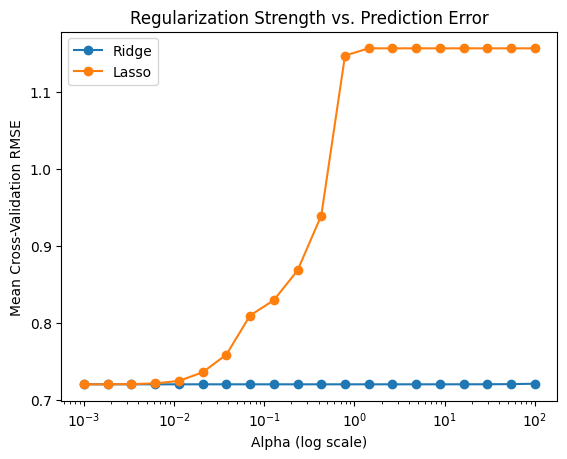

In [22]:
from sklearn.model_selection import cross_val_score, KFold
import matplotlib.pyplot as plt

alphas = np.logspace(-3, 2, 20)

cv = KFold(n_splits=5, shuffle=True, random_state=42)

rows = []

for alpha in alphas:
    for name, estimator in [
        ("Ridge", Ridge(alpha=alpha)),
        ("Lasso", Lasso(alpha=alpha, max_iter=20000))
    ]:
        pipeline = make_pipeline(StandardScaler(), estimator)

        scores = cross_val_score(
            pipeline,
            X_train,
            y_train,
            scoring="neg_root_mean_squared_error",
            cv=cv,
            n_jobs=-1
        )

        rows.append({
            "Model": name,
            "Alpha": alpha,
            "CV RMSE": -scores.mean()
        })

alpha_results = pd.DataFrame(rows)

for name in ["Ridge", "Lasso"]:
    subset = alpha_results[alpha_results["Model"] == name]
    plt.plot(subset["Alpha"], subset["CV RMSE"], marker="o", label=name)

plt.xscale("log")
plt.xlabel("Alpha (log scale)")
plt.ylabel("Mean Cross-Validation RMSE")
plt.title("Regularization Strength vs. Prediction Error")
plt.legend()
plt.show()

In [23]:
cv = KFold(n_splits=5, shuffle=True, random_state=42)

alpha_values = np.logspace(-5, -2, 13)

models_to_test = {
    "Linear Regression": make_pipeline(
        StandardScaler(),
        LinearRegression()
    )
}

for alpha in alpha_values:
    models_to_test[f"Ridge alpha={alpha:.5g}"] = make_pipeline(
        StandardScaler(),
        Ridge(alpha=alpha)
    )

    models_to_test[f"Lasso alpha={alpha:.5g}"] = make_pipeline(
        StandardScaler(),
        Lasso(alpha=alpha, max_iter=30000)
    )

rows = []

for name, model in models_to_test.items():
    scores = cross_val_score(
        model,
        X_train,
        y_train,
        scoring="neg_root_mean_squared_error",
        cv=cv,
        n_jobs=-1
    )

    rows.append({
        "Model": name,
        "Mean CV RMSE": -scores.mean(),
        "Std CV RMSE": scores.std()
    })

comparison = pd.DataFrame(rows).sort_values("Mean CV RMSE")

display(comparison.head(10).round(6))

,Model,Mean CV RMSE,Std CV RMSE
16,Lasso alpha=0.00056234,0.720494,0.013871
14,Lasso alpha=0.00031623,0.720498,0.013882
18,Lasso alpha=0.001,0.720499,0.013853
12,Lasso alpha=0.00017783,0.720502,0.013887
10,Lasso alpha=0.0001,0.720505,0.013891
8,Lasso alpha=5.6234e-05,0.720507,0.013892
6,Lasso alpha=3.1623e-05,0.720508,0.013893
4,Lasso alpha=1.7783e-05,0.720509,0.013894
2,Lasso alpha=1e-05,0.720509,0.013894
25,Ridge alpha=0.01,0.720510,0.013895


In [24]:
finalists = {
    "Linear Regression": LinearRegression(),
    "Ridge": Ridge(alpha=3.1622776602),
    "Lasso": Lasso(alpha=0.0005623413, max_iter=30000)
}

test_results = []

for name, estimator in finalists.items():
    model = make_pipeline(
        StandardScaler(),
        estimator
    )

    model.fit(X_train, y_train)

    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    test_results.append({
        "Model": name,
        "Train RMSE": root_mean_squared_error(y_train, train_pred),
        "Test RMSE": root_mean_squared_error(y_test, test_pred),
        "Train R2": r2_score(y_train, train_pred),
        "Test R2": r2_score(y_test, test_pred)
    })

test_results_df = pd.DataFrame(test_results)
display(test_results_df.round(6))

,Model,Train RMSE,Test RMSE,Train R2,Test R2
0,Linear Regression,0.719676,0.745581,0.612551,0.575788
1,Ridge,0.719676,0.745504,0.612550,0.575876
2,Lasso,0.719688,0.745041,0.612538,0.576402


## Conclusion

This experiment compared Linear Regression, Ridge Regression, and Lasso Regression on the California Housing dataset.

The models were evaluated using RMSE and R², with regularization strength selected using 5-fold cross-validation.

The final results showed that Lasso achieved the lowest test RMSE and highest test R². However, the improvement over Linear Regression was very small.

The coefficient analysis demonstrated the difference between L1 and L2 regularization. Ridge gradually shrank coefficients toward zero, while Lasso was able to reduce coefficients to exactly zero as the regularization strength increased.

Overall, regularization provided only a marginal improvement for this dataset, but the experiment demonstrated how the choice of alpha affects model complexity, coefficient values, and predictive performance.